# Forecasting daily mentions of Lenin and Stalin on Russian television
**Купча Софья · Пальцева Ксения**

Воспроизводимый итоговый проект. Цели: количество упоминаний фамилии C и количество архивных записей с ≥1 упоминанием B; два человека, четыре канала, 16 рядов. Прогноз: **3 октября — 2 ноября 2026**. Информация ограничена **2 октября 2026**: это frozen-cutoff прогноз, а не заявление о сегодняшнем информационном наборе.

Инструкция преподавателя требует `.ipynb`, объяснения каждого вычислительного шага и доступных данных. Все модели и процедуры находятся в поставляемых `analysis/joint_count_models.py`, `run_joint_forecast.py`, `verify_joint_forecast.py`, `forecast_artifacts.py`. Этот ноутбук вызывает те же функции; кэш можно полностью перестроить. Исходная заявка: `output/proposal/forecasting_proposal.tex`.

## 1. Запуск и данные
Устанавливаем `requirements-forecast.txt` из корня проекта. Данные читаются из `data/cleaned/tv_daily_targets.csv.gz`; этот сжатый набор включён в проект. Восстановление из оригиналов: `python analysis/prepare_clean_data.py`. Правила отбора и ограничения описаны в `output/data_cleaning/README.md`; нейросетевой эксперимент отменён и на эти результаты не влияет.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, SVG, HTML
candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p/'analysis/joint_count_models.py').exists())
sys.path.insert(0, str(ROOT/'analysis'))
import joint_count_models as models
from run_joint_forecast import run_experiment
from verify_joint_forecast import verify
OUT = ROOT/'output/joint_forecast'
data, input_sha = models.load_data()
display(data.groupby('channel').agg(days=('day','size'), observed=('observed','sum'),
                                  mean_records=('available_broadcasts','mean')))
print('Last observation:', data.date.max().date(), '| input SHA-256:', input_sha)

Last observation: 2026-10-02 | input SHA-256: bb18df725a91029b0116ca750b5e8398ad89c3d3d61f3e5ef32661b31cc04b63


,days,observed,mean_records
channel,,,
1TV,1371,1331,14.556528
NTV,1371,1347,10.305616
RUSSIA1,1371,1319,12.821298
RUSSIA24,1371,1337,46.059810


Полнота дня проверяется по UTC-инвентарям и доступным транскриптам; агрегация использует MSK-день начала записи. Неполные дни отсутствуют в likelihood и оценке, они не становятся нулями. Удаляются лишь доказанные совпадения упоминаний в перекрывающихся записях. Основная метка `person_likely` предварительная; расширенный ряд добавляет неясные ссылки и ASR.

Политическая риторика мотивирует задачу, но прогнозируемый объект уже: счётчики фамилий в архивных текстах. Длина транскриптов, повторы и ошибки ASR ограничивают такую интерпретацию.

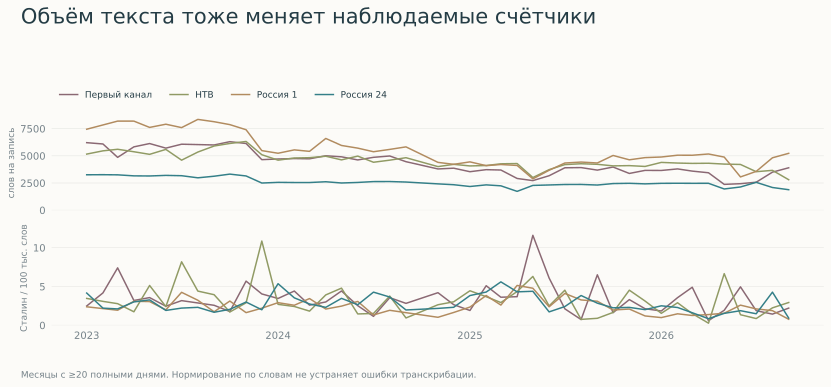

In [2]:
if (OUT/'figures/text_volume.svg').exists():
    display(SVG(filename=str(OUT/'figures/text_volume.svg')))
else:
    print('График объёма текста будет создан после расчёта в разделе 4.')

## 2. Генеративная зависимость счётчиков
Комментарий преподавателя требует уважать зависимость N, B и C. Используем
$$p(N,B_L,C_L,B_S,C_S)=p(N)\prod_{r\in\{L,S\}}p(B_r\mid N)\,p(C_r\mid B_r).$$
У каждого положительного архива есть хотя бы одно упоминание: $C=B+E$. При $B=0$ полагаем $E=0$. Поэтому $0\le B\le N$ и $C\ge B$ во всех реализациях. Это не независимые прогнозы, исправленные после расчёта. Остаточная связь между двумя людьми сверх общего N пока не моделируется.

### M1: аналитический Bayesian baseline (L2)
$N_t\sim Poisson(\lambda_N)$, $B_t\mid N_t\sim Binomial(N_t,p)$,
$E_t\mid B_t\sim Poisson(B_t\lambda_E)$.
Независимые априорные распределения по каналам: $\lambda_N\sim Gamma(2,0.1)$, $p\sim Beta(1,19)$, $\lambda_E\sim Gamma(1,1)$; второй аргумент Gamma — rate.
Posterior: $Gamma(2+\sum N,0.1+n)$; $Beta(1+\sum B,19+\sum(N-B))$; $Gamma(1+\sum E,1+\sum B)$. Одна posterior-параметризация сохраняется на всю месячную траекторию, что переносит неопределённость параметров в месячный итог.

### M2: избыточная вариация (L2–L3)
$N_t\sim NB(\mu_{Nt},k_N)$, $B_t\mid N_t\sim BetaBinomial(N_t,p_t\phi,(1-p_t)\phi)$.
$E_t\mid B_t>0\sim NB(B_t\lambda_{Et},B_t k_E)$. Последняя формула есть сумма B независимых дополнительных счётчиков NB с одинаковым per-record размером k. В параметризации NB $Var(Y)=\mu+\mu^2/k$.
Для каждого компонента используются общий уровень и ортонормальные контрасты каналов. Dispersion разделяется каналами внутри компонента. Различия людей имеют отдельные модели B и E.
Приоры общего уровня (SD=1.5): N — Normal(log 20,1.5²), B — Normal(logit 0.05,1.5²), E — Normal(0,1.5²). Приоры log-dispersion с тем же SD: log k_N — Normal(log 5,1.5²), log phi — Normal(log 20,1.5²), log k_E — Normal(0,1.5²). Время центрируется по обучающим датам, не по будущим исходам.

### M3: календарь, тренд и partial pooling (L4)
В log/logit-предиктор добавляются линейный тренд в годах, 11 суммирующихся в ноль месячных и 6 недельных контрастов. Календарь общий для каналов внутри компонента; отклонения каналов сжимаются к общему уровню. Контрасты месяца имеют $N(0,0.35^2)$, дня недели $N(0,0.25^2)$, канала $N(0,0.8^2)$; тренд $N(0,0.35^2)$.
Точные даты и дни на расстоянии 1–2 дней моделируются отдельно: 7 ноября, 8 мая, 9 мая, рождение и смерть Ленина, смерть и официальная дата рождения Сталина. Коэффициенты точной даты $N(0,0.7^2)$, соседних дней $N(0,0.5^2)$.
Это prior-specified partial pooling: гипермасштабы фиксированы заранее, а не оценены из данных. Близкие праздники могут быть слабо различимы на трёх годовых повторах. 7 ноября вне финального горизонта; его индикатор присутствует в модели, а не добавлен в прогноз искусственно.

## 3. Bayesian computation и последовательное обновление
Статические M2/M3 используют Metropolis–Hastings с точным likelihood × prior (L3). Мода и численный Hessian задают многомерное Student-t предложение с df=12; это не замена posterior на Gaussian. Начальные точки и случайные потоки четырёх цепей различаются. Warmup отбрасывается. При $\hat R\ge1.01$ или bulk/tail ESS <400 расчёт повторяется с удвоенным числом итераций; неудачная сходимость останавливает workflow.

**M4 (L5):** $s_{t}=s_{t-1}+\epsilon_t$, $\epsilon_t\sim N(0,q^2)$ на log/logit-шкале каждого компонента/канала. Статические параметры берутся из M3. Для каждого такого draw работает отдельный условный particle filter: propagate, likelihood weighting, normalize, systematic resampling при ESS < P/2. В неполный день выполняется только propagate; при B=0 параметр избыточных упоминаний не обновляется. Начало 365-дневного окна: $s\sim N(0,0.25^2)$.
Это **cut/modular approximation**: static posterior уже оценён на том же обучении, затем состояния фильтруются условно, без переоценки весов static draws. Уверенность может отличаться от полного совместного Bayes. Динамический уровень распространяется и на будущие дни, поэтому интервалы должны учитывать будущие инновации.

**Смесь (L6):** с вероятностью 1/4 выбираем целую траекторию M1, M2, M3 или M4. Это linear pool распределений, не усреднение квантилей и не BMA. Равные веса не подгоняются на тесте.

## 4. Честная временная проверка
Шесть validation-месяцев: июль–декабрь 2024. На них выбираем q ∈ {0.015,0.04,0.08} по среднему месячных средних scaled CRPS модели M4 (равный вес месяцев), затем выбираем один из M1–M4/смеси по всем дневным forecast cases. Внешний test: январь 2025–сентябрь 2026, 21 непересекающийся календарный месяц. Перед каждым origin переобучаемся на расширяющемся прошлом. Случайного train/test split нет.

Основная оценка: ежедневный CRPS; для сопоставления масштабов делим его на max(1, среднее соответствующего ряда в обучении). Отдельно сохраняем обычный CRPS, RMSE по posterior predictive mean, покрытие и ширину интервалов 80/95%, PIT, оценки по горизонту. Для месячных исходов требуем полного наблюдения всех дней.

Следующая ячейка может пересчитать ВСЕ модели, backtest и чувствительность. По умолчанию используются результаты завершённого расчёта; `RUN_REBUILD=True` принудительно переоценивает posterior. Эквивалент из терминала: `python analysis/run_joint_forecast.py --rebuild`.

In [3]:
RUN_REBUILD = False
if RUN_REBUILD or not (OUT/'manifest.json').exists():
    run_experiment(jobs=1, rebuild=RUN_REBUILD)
    from forecast_artifacts import build_artifacts
    build_artifacts()
verification = verify()
manifest = json.loads((OUT/'manifest.json').read_text(encoding='utf-8'))
selection = json.loads((OUT/'selection.json').read_text(encoding='utf-8'))
display(pd.Series(selection, name='Frozen validation selection'))
print('Verification:', verification['status'], '| max Rhat:', verification['max_rhat'])

Forecast verification PASS.
Verification: pass | max Rhat: 1.0097665475460946


q                                                                0.015
selected_model                                                      M3
criterion                mean daily CRPS / max(training series mean,1)
validation_months                                                    6
validation_scores    {'M3': 0.5459581207043673, 'POOL': 0.549821004...
pool_weights          {'M1': 0.25, 'M2': 0.25, 'M3': 0.25, 'M4': 0.25}
Name: Frozen validation selection, dtype: object

CRPS вычисляется как $E|X-y|-\frac12E|X-X'|$ с точной формулой для эмпирического predictive-распределения. Число реализаций в backtest — 2048, финально — 30000. Малые различия scores могут отражать Monte Carlo noise. Неопределённость skill на рисунке получена circular moving-block bootstrap по месяцам, длина блока 3; все цели внутри месяца остаются вместе.
Рандомизированный PIT использует $F(y^-)+U\,[F(y)-F(y^-)]$ для дискретного распределения. Плоская объединённая гистограмма не устанавливает ни условную калибровку, ни независимость ошибок (S2). Здесь прогноз многодневный; исходы внутри месячной траектории связаны. Из-за целочисленных границ интервалы счётчиков могут иметь покрытие выше номинала даже у правильной модели; поэтому одновременно смотрим CRPS, PIT и ширину.

,model,rmse,crps,scaled_crps,coverage80,coverage95,width80,width95
0,M1,2.4242,0.7981,0.5056,0.9453,0.9753,3.3776,5.0789
1,M2,2.4275,0.7384,0.4711,0.9579,0.9891,3.7302,8.2163
2,M3,2.3829,0.7115,0.4542,0.9378,0.9851,2.9325,6.7445
3,M4,2.3859,0.7117,0.4546,0.9384,0.9841,2.9687,6.7562
4,POOL,2.3869,0.7226,0.4609,0.9485,0.9847,3.2873,6.6374


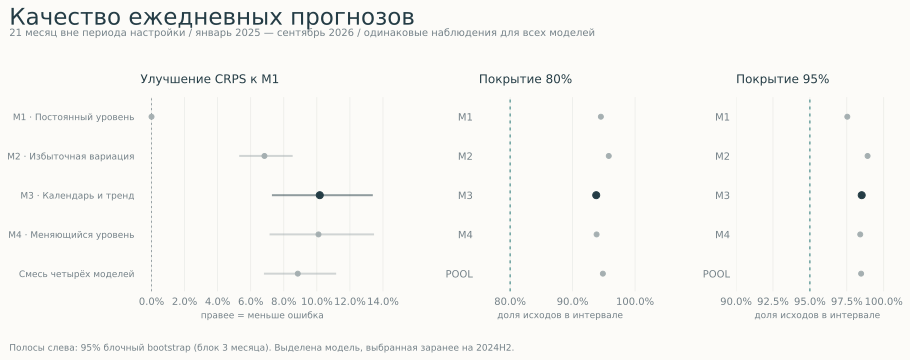

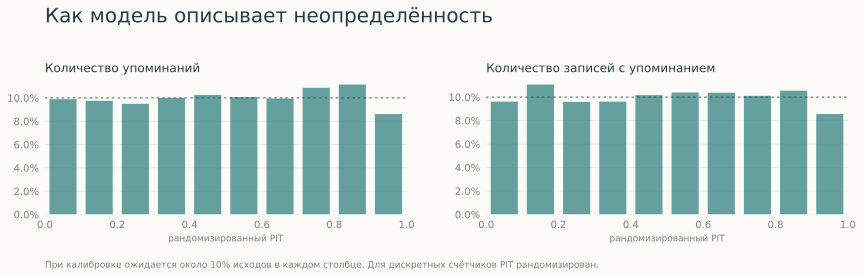

In [4]:
evaluation = pd.read_csv(OUT/'evaluation.csv')
display(evaluation[['model','rmse','crps','scaled_crps','coverage80','coverage95','width80','width95']].round(4))
display(SVG(filename=str(OUT/'figures/backtest_quality.svg')))
display(SVG(filename=str(OUT/'figures/calibration.svg')))

Diebold–Mariano сравнивает средние парные потери по 21 месячному блоку. Используем Bartlett HAC с lag=1 для зависимости между соседними месяцами. Наблюдения/каналы/люди внутри месяца не объявляются независимыми. Положительная разность означает выигрыш относительно M1. Поправка Holm применяется отдельно к четырём сравнениям по каждому из двух типов потерь. При 21 блоке p-values приблизительны; это описательная проверка различий, а не доказательство универсального превосходства.

,loss,baseline,model,origins,hac_lag,improvement,dm_statistic,p_value,p_holm
0,scaled_crps,M1,M2,21,1,0.0344,12.7961,0.0000,0.0000
1,scaled_crps,M1,M3,21,1,0.0511,8.4413,0.0000,0.0000
2,scaled_crps,M1,M4,21,1,0.0506,7.8588,0.0000,0.0000
3,scaled_crps,M1,POOL,21,1,0.0445,11.8468,0.0000,0.0000
4,scaled_se,M1,M2,21,1,-0.0041,-1.7850,0.0743,0.2228
5,scaled_se,M1,M3,21,1,0.0694,1.4281,0.1533,0.3065
6,scaled_se,M1,M4,21,1,0.0658,1.3508,0.1768,0.3065
7,scaled_se,M1,POOL,21,1,0.0660,3.7051,0.0002,0.0008


,model,horizon_band,n,origins,rmse,crps,scaled_crps,scaled_rmse,coverage80,coverage95,width80,width95
0,M1,1–7,2328.0,21.0,2.8577,0.8502,0.5159,1.4268,0.9424,0.9712,3.3836,5.0820
1,M1,8–14,2292.0,21.0,2.3690,0.7691,0.4794,1.2996,0.9564,0.9795,3.3783,5.0686
2,M1,15–21,2320.0,21.0,2.1210,0.7525,0.4824,1.2446,0.9496,0.9793,3.3754,5.0752
3,M1,22–31,3112.0,21.0,2.3207,0.8145,0.5346,1.4744,0.9361,0.9724,3.3741,5.0869
4,M2,1–7,2328.0,21.0,2.8572,0.7886,0.4776,1.4277,0.9536,0.9884,3.7374,8.2297
5,M2,8–14,2292.0,21.0,2.3740,0.7136,0.4483,1.3015,0.9664,0.9900,3.7318,8.2226
6,M2,15–21,2320.0,21.0,2.1296,0.6743,0.4387,1.2462,0.9638,0.9909,3.7249,8.1975
7,M2,22–31,3112.0,21.0,2.3229,0.7669,0.5072,1.4760,0.9505,0.9875,3.7276,8.2158
8,M3,1–7,2328.0,21.0,2.8333,0.7627,0.4568,1.3878,0.9381,0.9832,2.9344,6.7322
9,M3,8–14,2292.0,21.0,2.2665,0.6722,0.4250,1.2420,0.9498,0.9873,2.9616,6.7212


,model,complete_month_targets,origins,rmse,crps,coverage80,coverage95,width80,width95
0,M1,280.0,21.0,21.503,12.238,0.379,0.546,22.015,33.489
1,M2,280.0,21.0,21.951,11.112,0.521,0.771,34.872,54.255
2,M3,280.0,21.0,18.568,8.236,0.721,0.900,30.515,48.392
3,M4,280.0,21.0,18.576,8.160,0.779,0.918,33.023,52.779
4,POOL,280.0,21.0,19.178,9.066,0.707,0.900,33.666,53.001


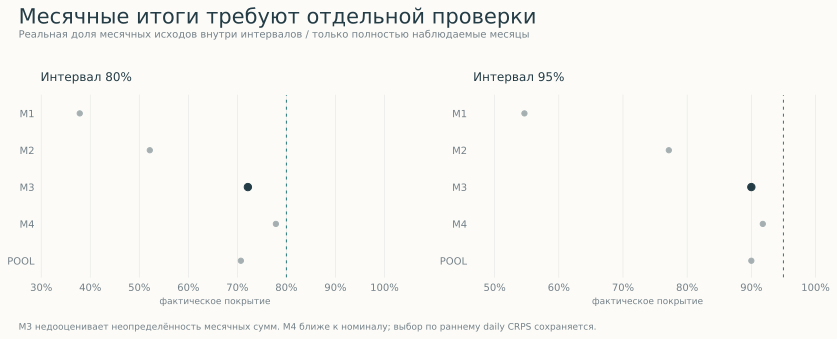

In [5]:
display(pd.read_csv(OUT/'dm_tests.csv').round(4))
display(pd.read_csv(OUT/'evaluation_by_horizon.csv').round(4))
display(pd.read_csv(OUT/'evaluation_monthly.csv').round(3))
display(SVG(filename=str(OUT/'figures/monthly_quality.svg')))

## 5. Итоговый прогноз
После фиксации выбора переобучаемся на всех полных днях до 2 октября 2026. Выдаём все модели и заранее выбранный основной прогноз. Месячные интервалы получаем **по суммам каждой совместной траектории**, а не сложением квантилей по дням. Показываем predictive intervals для наблюдаемых счётчиков, а не только uncertainty среднего уровня.

,channel,target,mean,lo80,hi80,lo95,hi95
44,1TV,lenin_broadcasts,12.8,7.0,19.0,5.0,22.0
45,NTV,lenin_broadcasts,9.5,5.0,14.0,3.0,17.0
46,RUSSIA1,lenin_broadcasts,13.9,8.0,20.0,6.0,24.0
47,RUSSIA24,lenin_broadcasts,24.1,15.0,34.0,11.0,41.0
48,1TV,lenin_mentions,25.5,11.0,43.0,7.0,59.0
49,NTV,lenin_mentions,24.0,8.0,45.0,4.0,66.0
50,RUSSIA1,lenin_mentions,26.0,12.0,43.0,8.0,56.0
51,RUSSIA24,lenin_mentions,38.0,21.0,58.0,15.0,72.0
52,1TV,stalin_broadcasts,16.8,10.0,24.0,8.0,28.0
53,NTV,stalin_broadcasts,8.2,4.0,13.0,3.0,16.0


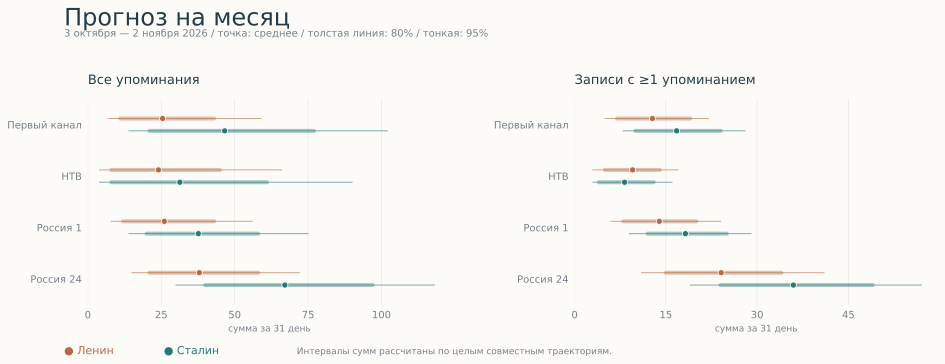

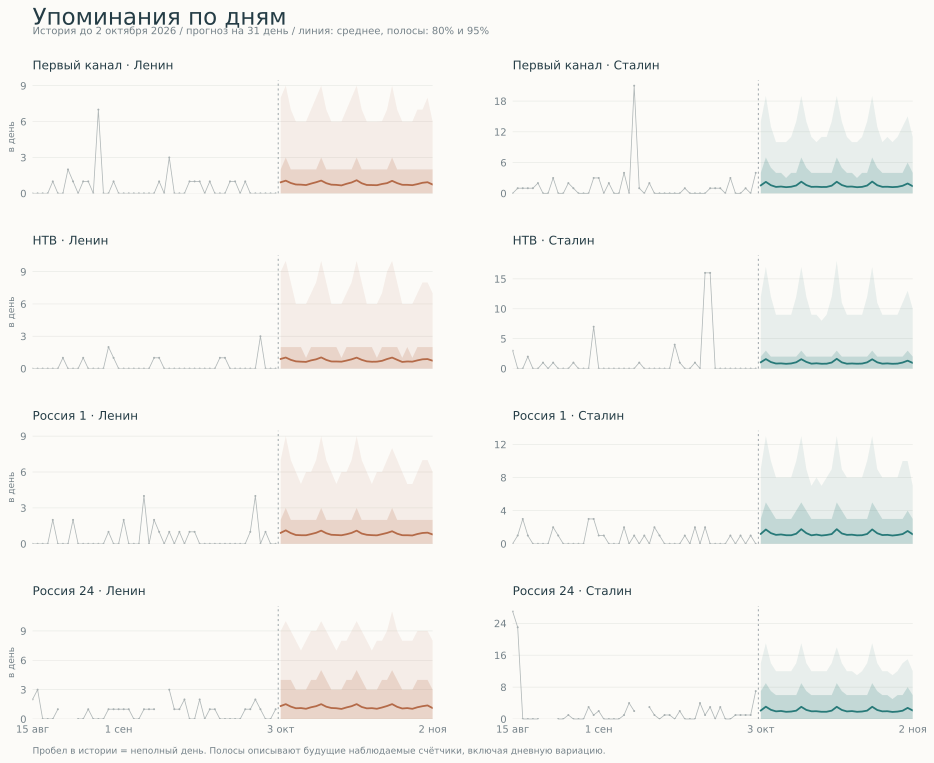

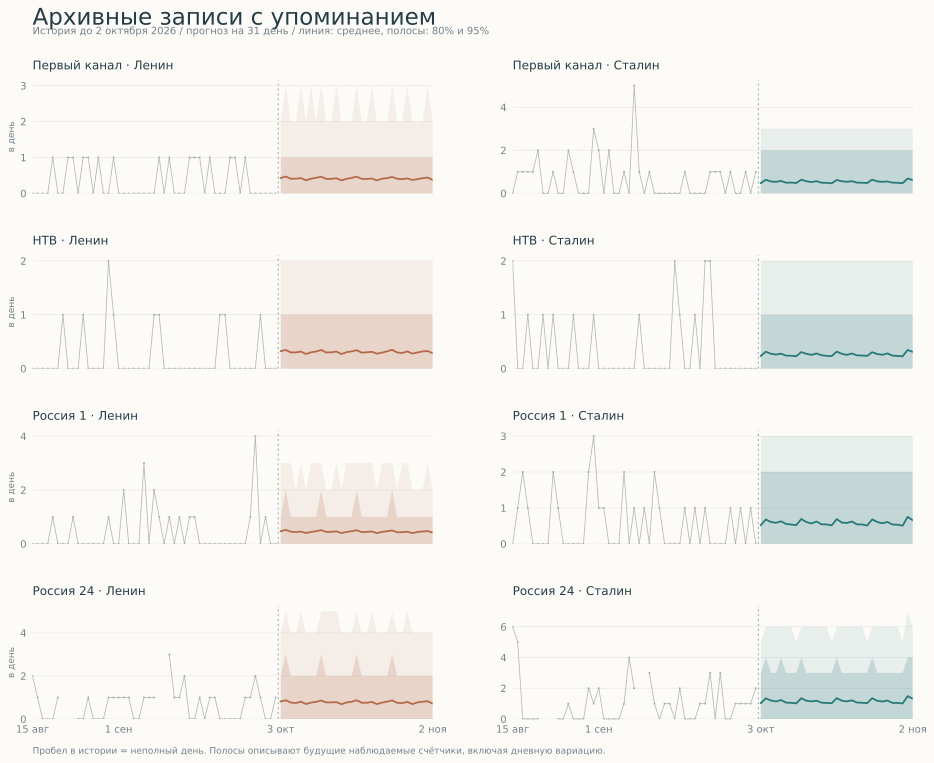

In [6]:
monthly = pd.read_csv(OUT/'forecast_month.csv')
main = monthly[(monthly.scenario=='main') & (monthly.model==manifest['selected_model']) & (monthly.target!='N')]
display(main[['channel','target','mean','lo80','hi80','lo95','hi95']].round(1))
display(SVG(filename=str(OUT/'figures/month_overview.svg')))
display(SVG(filename=str(OUT/'figures/daily_mentions.svg')))
display(SVG(filename=str(OUT/'figures/daily_broadcasts.svg')))

## 6. Проверки адекватности и чувствительности
Posterior predictive checks сравнивают реальные mean/variance/zero-share/p95 за последний год с репликациями M1–M3. Это in-sample проверка модели, **не внешний test**. Неудачные проверки сохраняются и обсуждаются; правильная сходимость MCMC не означает правильной модели. Отдельно смотрим чувствительность particle filter к большему числу static draws и частиц; разница включает фильтровый Monte Carlo error, который нельзя оценить только по SE финальных траекторий.

Расширенный ряд неясных контекстов переоценивается с теми же моделями и q, без нового выбора на тесте. Это сценарий измерения, не доказанная верхняя граница. Интервалы основного прогноза не интегрируют всю ошибку классификации.
Исторический backtest ретроспективный: используется одна исправленная версия архива и единое определение меток. Исторические real-time vintages транскриптов и меток отсутствуют; их доступность именно в момент каждого origin не подтверждена.

sum  count
model statistic             
M1    mean         14     16
      p95           3     16
      variance     12     16
      zero_share   14     16
M2    mean         13     16
      p95           7     16
      variance     10     16
      zero_share   10     16
M3    mean          2     16
      p95           1     16
      variance      3     16
      zero_share    0     16

,channel,target,original_mean,more_particles_mean,relative_difference,simulation_se_conditional
0,1TV,N,479.818,481.543,0.004,0.510
1,NTV,N,442.793,440.622,-0.005,0.464
2,RUSSIA1,N,385.431,386.743,0.003,0.441
3,RUSSIA24,N,1879.842,1884.220,0.002,1.606
4,1TV,lenin_broadcasts,11.034,11.131,0.009,0.053
5,NTV,lenin_broadcasts,13.223,13.095,-0.010,0.057
6,RUSSIA1,lenin_broadcasts,11.965,12.048,0.007,0.054
7,RUSSIA24,lenin_broadcasts,33.995,33.816,-0.005,0.128
8,1TV,lenin_mentions,24.716,24.984,0.011,0.189
9,NTV,lenin_mentions,28.974,28.701,-0.009,0.203


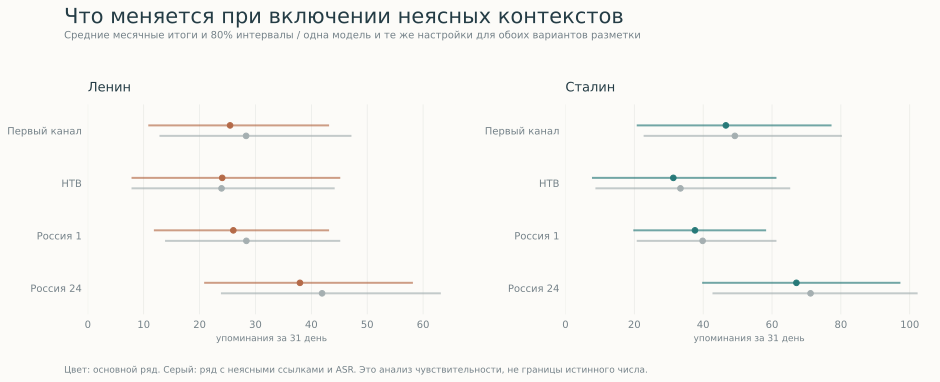

,person,effect,lo95,lo80,median,hi80,hi95
0,lenin,exact_nov7,0.43,0.62,1.07,1.77,2.21
1,lenin,exact_may8,0.75,0.94,1.46,2.24,2.76
2,lenin,exact_may9,0.79,0.99,1.62,2.56,3.43
3,stalin,exact_nov7,0.78,0.97,1.49,2.17,2.66
4,stalin,exact_may8,1.50,1.82,2.47,3.41,4.05
5,stalin,exact_may9,0.99,1.22,1.70,2.40,2.86


In [7]:
checks = pd.read_csv(OUT/'posterior_predictive_checks.csv')
display(checks.groupby(['model','statistic']).outside95.agg(['sum','count']))
display(pd.read_csv(OUT/'particle_sensitivity.csv').round(3))
display(SVG(filename=str(OUT/'figures/context_sensitivity.svg')))
display(pd.read_csv(OUT/'calendar_effects.csv').round(2))

Коэффициенты календаря в последней таблице — odds ratios точного дня в B-компоненте M3, условно на остальные признаки; это не причинные эффекты и не мультипликаторы общего числа упоминаний.

## 7. Выводы и ограничения

In [8]:
display(HTML((OUT/'findings.html').read_text(encoding='utf-8')))

## 8. Связь с курсом и воспроизводимость
| Материал | Применение в проекте |
|---|---|
| L1 / S1 Forecast evaluation | Среднее для squared loss; CRPS, calibration/sharpness, одинаковые forecast cases |
| L2 / S2 Bayesian forecasting | Сопряжённый baseline, posterior predictive, PPC; uncertainty параметров и наблюдений |
| L3 / S3 Bayesian computation | Точный MH, несколько цепей, warmup, Rhat и ESS, независимые численные проверки |
| L4 / S4 Hierarchical models | Общий уровень и shrinkage каналов/календаря, явные фиксированные гипермасштабы |
| L5 / S5 Sequential forecasting | Латентный уровень, propagate–weight–resample, ESS и пропущенные измерения |
| L6 / S6 Forecast aggregation | Смесь распределений, целые траектории, отдельный внешний test |
| Комментарий Марата | Праздничные индикаторы; разграничение человека и названного объекта; N→B→C |

Техническая сверка параметризаций: [SciPy NB](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.nbinom.html), [SciPy Beta-binomial](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.betabinom.html), [Stan: диагностика цепей](https://mc-stan.org/learn-stan/diagnostics-warnings.html). Основные материалы — предоставленные лекции и семинары курса.

Все исходные вычисления доступны в четырёх Python-модулях выше. Их SHA-256 и версии окружения записаны в manifest; данные для модели доступны локально в исправленной сжатой таблице. Фиксированные seed обеспечивают повторяемые случайные потоки. Корпус оригиналов можно перепроверить отдельно по документации очистки; для запуска прогноза Google Cloud и внешние API не требуются.

In [9]:
display(pd.Series(manifest['versions'], name='Environment'))
display(pd.Series(manifest['code_sha256'], name='Executable SHA-256'))
print('Data SHA-256:', manifest['source_sha256'])

Data SHA-256: bb18df725a91029b0116ca750b5e8398ad89c3d3d61f3e5ef32661b31cc04b63


python        3.13.7
numpy          2.3.2
pandas         2.3.2
scipy         1.16.1
matplotlib    3.11.2
arviz         0.23.4
Name: Environment, dtype: object

execute_forecast_notebook.py    7ab9ba4c83058f163f1a108635607eec587676fe8feec3...
forecast_artifacts.py           42c97c80eeea854460aab55ead2452acb0fca97b1ce581...
run_joint_forecast.py           7f4de7c31992d0c164cb4dc02780176e97dd040409a750...
verify_forecast.py              86e987e1f01066e621b699230658723f0c427e8595426f...
verify_joint_forecast.py        ef99e0673aa09cf2041308d96381df9e30cd4b9450d50f...
joint_count_models.py           1392f640fd5be29a8f121de0740b5556aaa39f39ea871c...
Name: Executable SHA-256, dtype: object